In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [3]:
movies = pd.read_csv('../data/raw/ml-32m/movies.csv', low_memory=False)
print(movies.shape)
movies.head()

(87585, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [18]:
# Deduped movies by title
n_dist_titles = len(movies.drop_duplicates(subset='title', keep='first'))
print(f"Distinct titles: {n_dist_titles:,}")
display(movies['title'].value_counts().head(10))
movies[movies['title'] == 'Alone (2020)']

Distinct titles: 87,382


title
Alone (2020)                                 4
Journey to the Center of the Earth (2008)    3
The Plague (2006)                            3
The Box (2021)                               3
Aladdin (1992)                               2
Men with Guns (1997)                         2
Dracula (1931)                               2
Saturn 3 (1980)                              2
Gossip (2000)                                2
Hamlet (2000)                                2
Name: count, dtype: int64

,movieId,title,genres
65389,212511,Alone (2020),Thriller
69290,223191,Alone (2020),Horror|Thriller
69683,224463,Alone (2020),Thriller
81319,273117,Alone (2020),Sci-Fi


In [23]:
# get distinct genres
dist_genres = list(movies['genres'].str.split('|').explode().unique())
dist_genres

['Adventure',
 'Animation',
 'Children',
 'Comedy',
 'Fantasy',
 'Romance',
 'Drama',
 'Action',
 'Crime',
 'Thriller',
 'Horror',
 'Mystery',
 'Sci-Fi',
 'IMAX',
 'Documentary',
 'War',
 'Musical',
 'Western',
 'Film-Noir',
 '(no genres listed)']

In [ ]:
def combine_genres(movies_df: pd.DataFrame) -> pd.DataFrame:
    """
    Combine genres into a single column for each movie.

    e.g. Alone (2020) has genres: Horror, Thriller, and Sci-Fi
    so for each occurence of Alone (2020), we will have: Horror|Thriller|Sci-Fi
    
    Args:
        movies_df (pd.DataFrame): DataFrame containing movie data with 'title'
                                  and 'genres' columns.
    Returns:
        pd.DataFrame: DataFrame with an additional 'combined_genres' column.
    """

    # Create a new column for combined genres
    movies_df['combined_genres'] = movies_df.groupby('title')['genres'].transform(lambda x: '|'.join(x.unique()))
    movies_df['combined_genres'] = movies_df['combined_genres'].apply(
        lambda x: '|'.join(sorted(set(x.split('|')))) if pd.notnull(x) else x)
        
    return movies_df


movies = combine_genres(movies)
movies[movies['title'] == 'Alone (2020)']

,movieId,title,genres,combined_genres
65389,212511,Alone (2020),Thriller,Horror|Sci-Fi|Thriller
69290,223191,Alone (2020),Horror|Thriller,Horror|Sci-Fi|Thriller
69683,224463,Alone (2020),Thriller,Horror|Sci-Fi|Thriller
81319,273117,Alone (2020),Sci-Fi,Horror|Sci-Fi|Thriller


In [4]:
links = pd.read_csv('../data/raw/ml-32m/links.csv', low_memory=False)
print(links.shape)
links.head()

(87585, 3)


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [5]:
ratings = pd.read_csv('../data/raw/ml-32m/ratings.csv', low_memory=False)
print(ratings.shape)
ratings.head()

(32000204, 4)


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [30]:
ratings['rating'].value_counts().sort_index()

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64

[np.float64(0.5),
 np.float64(1.0),
 np.float64(1.5),
 np.float64(2.0),
 np.float64(2.5),
 np.float64(3.0),
 np.float64(3.5),
 np.float64(4.0),
 np.float64(4.5),
 np.float64(5.0)]

Distinct users: 200,948
Range of ratings: 0.5 to 5.0


ValueError: 'locs' must be 1D with shape (N,), but your input has shape (1, 10)

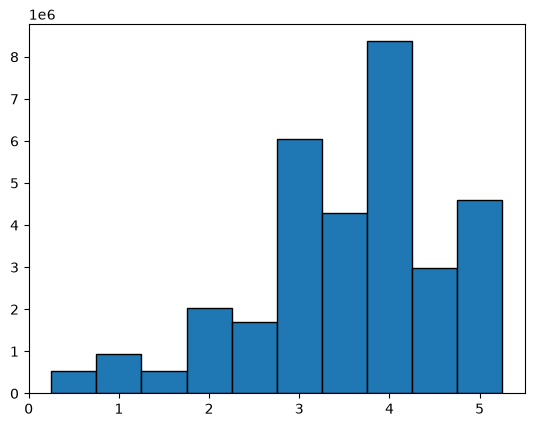

In [ ]:
print(f"Distinct users: {ratings['userId'].nunique():,}")
print("Range of ratings:", ratings['rating'].min(), "to", ratings['rating'].max())
plt.bar(
    x=sorted(ratings['rating'].unique()),
    height=ratings['rating'].value_counts().sort_index(),
    width=0.5,
    edgecolor='black'
)
# plt.yticks()

In [6]:
tags = pd.read_csv('../data/raw/ml-32m/tags.csv', low_memory=False)
print(tags.shape)
tags.head()

(2000072, 4)


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102
